# Proyek Analisis Data: Air Quality Dataset (Beijing Multi-Site Data)
- **Nama:** vanaprastha2256
- **Email:** vanaprastha2256@dicoding.org
- **ID Dicoding:** vanaprastha2256

---

## Menentukan Pertanyaan Bisnis

Untuk menghasilkan analisis yang terarah, dapat dipertanggungjawabkan, dan terukur, pertanyaan bisnis disusun secara terpisah untuk setiap fokus masalah dengan menerapkan metodologi **SMART Question** (*Specific, Measurable, Action-Oriented, Relevant, Time-bound*):

### Pertanyaan 1 (Tren Polutan Musiman & Bulanan):
> **"Bagaimana tren konsentrasi polutan partikulat utama ($PM_{2.5}$ dan $PM_{10}$) di Beijing sepanjang periode Maret 2013 hingga Februari 2017, serta pada bulan dan musim apa konsentrasi polutan mencapai nilai rata-rata tertinggi dan terendah?"**
- **Specific:** Fokus mengkaji dinamika konsentrasi polutan partikulat utama ($PM_{2.5}$ dan $PM_{10}$) secara agregat pada 12 stasiun pemantau udara di Beijing.
- **Measurable:** Diukur secara kuantitatif melalui nilai rata-rata konsentrasi polutan bulanan dan musiman ($\mu g/m^3$) serta perbandingannya terhadap standar baku mutu kualitas udara harian nasional Tiongkok ($75\ \mu g/m^3$ untuk $PM_{2.5}$ dan $150\ \mu g/m^3$ untuk $PM_{10}$).
- **Action-Oriented:** Mengidentifikasi periode musiman paling kritis sebagai dasar penetapan kebijakan musiman pemerintah kota (seperti pengaturan pengawasan pembakaran bahan bakar pemanas ruangan dan kesiapan fasilitas kesehatan).
- **Relevant:** Partikulat $PM_{2.5}$ dan $PM_{10}$ merupakan indikator utama kualitas udara ambien yang berdampak langsung terhadap kesehatan sistem pernapasan dan visibilitas atmosfer di Beijing.
- **Time-bound:** Periode analisis terikat jelas selama 4 tahun pengamatan: **1 Maret 2013 hingga 28 Februari 2017**.

### Pertanyaan 2 (Pola Fluktuasi Jam Harian / Diurnal):
> **"Bagaimana pola fluktuasi konsentrasi polutan udara per jam ($PM_{2.5}$, $PM_{10}$, $NO_2$, dan $O_3$) dalam siklus 24 jam (pukul 00:00–23:00) di Beijing selama periode 2013–2017, dan pada jam berapa konsentrasi masing-masing polutan mencapai titik puncak serta titik terendah?"**
- **Specific:** Mengkaji secara spesifik profil konsentrasi polutan per jam dari pukul 00:00 hingga 23:00 untuk membedakan perilaku polutan primer hasil pembakaran ($PM_{2.5}, PM_{10}, NO_2$) dan polutan fotokimia sekunder ($O_3$).
- **Measurable:** Dihitung dari nilai rata-rata konsentrasi per jam ($\mu g/m^3$) untuk setiap polutan sepanjang 24 jam.
- **Action-Oriented:** Mengidentifikasi jam-jam berisiko tinggi dalam sehari untuk memberikan rekomendasi operasional terkait pembatasan jam lalu lintas kendaraan berat dan panduan jam aman bagi masyarakat beraktivitas di luar ruangan.
- **Relevant:** Fluktuasi jam harian polutan sangat dipengaruhi oleh rutinitas aktivitas manusia (lalu lintas) dan dinamika atmosferik harian.
- **Time-bound:** Dianalisis menggunakan data per jam dari **Maret 2013 hingga Februari 2017**.

### Pertanyaan 3 (Perbandingan Spasial Antar-Stasiun):
> **"Bagaimana variasi konsentrasi rata-rata $PM_{2.5}$ antar-12 stasiun pemantau di Beijing selama periode 2013–2017, dan stasiun mana yang mencatat persentase jam dengan konsentrasi $PM_{2.5} > 75\ \mu g/m^3$ (kategori tidak sehat menurut standar harian Tiongkok) tertinggi serta terendah?"**
- **Specific:** Membandingkan kualitas udara antar-12 lokasi stasiun pemantau di Beijing untuk memetakan kesenjangan spasial wilayah perkotaan vs pinggiran/pedesaan.
- **Measurable:** Diukur melalui nilai konsentrasi rata-rata $PM_{2.5}$ ($\mu g/m^3$) per stasiun dan persentase (%) jam observasi dengan $PM_{2.5} > 75\ \mu g/m^3$.
- **Action-Oriented:** Menentukan stasiun/wilayah prioritas yang memerlukan intervensi pengendalian lingkungan paling mendesak serta mengidentifikasi kawasan penyangga dengan udara terbersih.
- **Relevant:** Pemetaan kualitas udara antar-wilayah krusial untuk penataan zonasi kota dan alokasi sumber daya pemantauan lingkungan hidup.
- **Time-bound:** Meliputi seluruh periode observasi penuh dari **1 Maret 2013 hingga 28 Februari 2017**.

### Pertanyaan Analisis Lanjutan (Geospatial & Clustering / AQI Binning):
> **"Bagaimana distribusi spasial stasiun pemantau di Beijing berdasarkan koordinat geografis dan bagaimana proporsi frekuensi kualitas udara berdasarkan 6 kategori baku mutu AQI $PM_{2.5}$, serta bagaimana hubungan linear parameter meteorologi terhadap konsentrasi polutan?"**
- Menerapkan **Geospatial Analysis** untuk pemetaan posisi stasiun di Beijing dan **Clustering (Manual Grouping / Binning)** untuk mengelompokkan jam pengamatan ke dalam 6 tingkatan baku mutu kualitas udara tanpa algoritma *machine learning*.

## Menyiapkan semua library yang dibutuhkan

Mengimpor seluruh pustaka Python yang digunakan untuk pengolahan data tabular, kalkulasi statistik numerik, serta pembuatan visualisasi data yang memenuhi standar integritas dan estetika visual.

In [1]:
import os
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Mengabaikan peringatan yang tidak memengaruhi hasil perhitungan
warnings.filterwarnings('ignore')

# Konfigurasi gaya visualisasi
sns.set_theme(style='whitegrid', palette='tab10')
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['figure.dpi'] = 120

print("Seluruh pustaka analisis berhasil dimuat!")

Seluruh pustaka analisis berhasil dimuat!


## Data Wrangling

Data Wrangling mencakup tahapan pengumpulan data (*Gathering*), penilaian kualitas data (*Assessing*), dan perbaikan data (*Cleaning*).

### Gathering Data

Memuat berkas CSV dari 12 stasiun pemantau udara Beijing dari folder `data/` dan menggabungkannya ke dalam satu DataFrame tunggal.

In [2]:
# Menemukan seluruh berkas CSV stasiun di direktori data/
file_paths = sorted(glob.glob('data/*.csv'))
print(f"Total berkas stasiun ditemukan: {len(file_paths)}")

# Memuat dan menggabungkan seluruh berkas stasiun
df_list = []
for path in file_paths:
    st_df = pd.read_csv(path)
    df_list.append(st_df)

raw_df = pd.concat(df_list, ignore_index=True)
print(f"Dimensi gabungan data mentah: {raw_df.shape[0]:,} baris dan {raw_df.shape[1]} kolom")
print(f"Daftar 12 Stasiun: {raw_df['station'].unique().tolist()}")

# Menampilkan 5 baris pertama data mentah
raw_df.head()

Total berkas stasiun ditemukan: 12


Dimensi gabungan data mentah: 420,768 baris dan 18 kolom
Daftar 12 Stasiun: ['Aotizhongxin', 'Changping', 'Dingling', 'Dongsi', 'Guanyuan', 'Gucheng', 'Huairou', 'Nongzhanguan', 'Shunyi', 'Tiantan', 'Wanliu', 'Wanshouxigong']


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


> [!NOTE]
> **Insight Gathering Data:**
> - Data mentah berhasil dihimpun dari 12 stasiun pemantau: *Aotizhongxin, Changping, Dingling, Dongsi, Guanyuan, Gucheng, Huairou, Nongzhanguan, Shunyi, Tiantan, Wanliu, dan Wanshouxigong*.
> - Setiap stasiun memiliki 35.064 baris observasi per jam, menghasilkan total keseluruhan **420.768 baris data** dan **18 kolom** yang mencakup data temporal, konsentrasi 6 polutan utama, 6 parameter cuaca, dan nama stasiun.

### Assessing Data

Memeriksa integritas data: tipe data, nilai yang hilang (*missing values*), duplikasi data, dan ringkasan statistik deskriptif untuk mengidentifikasi permasalahan data.

In [3]:
# 1. Struktur data dan tipe data
print("=== INFORMASI STRUKTUR DATA ===")
raw_df.info()

# 2. Pemeriksaan nilai hilang (Missing Values)
print("\n=== PEMERIKSAAN MISSING VALUES ===")
missing_df = pd.DataFrame({
    'Missing_Count': raw_df.isnull().sum(),
    'Percentage (%)': (raw_df.isnull().mean() * 100).round(2)
})
print(missing_df[missing_df['Missing_Count'] > 0])

# 3. Pemeriksaan data duplikat
print(f"\nJumlah baris duplikat identik: {raw_df.duplicated().sum()}")

# 4. Ringkasan statistik deskriptif data numerik
print("\n=== STATISTIK DESKRIPTIF DATA MENTAH ===")
raw_df.describe().round(2)

=== INFORMASI STRUKTUR DATA ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

=== PEMERIKS


Jumlah baris duplikat identik: 0

=== STATISTIK DESKRIPTIF DATA MENTAH ===


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.00,420768.00,420768.00,420768.00,420768.00,412029.00,414319.00,411747.00,408652.00,400067.00,407491.00,420370.00,420375.00,420365.00,420378.00,420450.00
mean,17532.50,2014.66,6.52,15.73,11.50,79.79,104.60,15.83,50.64,1230.77,57.37,13.54,1010.75,2.49,0.06,1.73
std,10122.12,1.18,3.45,8.80,6.92,80.82,91.77,21.65,35.13,1160.18,56.66,11.44,10.47,13.79,0.82,1.25
min,1.00,2013.00,1.00,1.00,0.00,2.00,2.00,0.29,1.03,100.00,0.21,-19.90,982.40,-43.40,0.00,0.00
25%,8766.75,2014.00,4.00,8.00,5.75,20.00,36.00,3.00,23.00,500.00,11.00,3.10,1002.30,-8.90,0.00,0.90
50%,17532.50,2015.00,7.00,16.00,11.50,55.00,82.00,7.00,43.00,900.00,45.00,14.50,1010.40,3.10,0.00,1.40
75%,26298.25,2016.00,10.00,23.00,17.25,111.00,145.00,20.00,71.00,1500.00,82.00,23.30,1019.00,15.10,0.00,2.20
max,35064.00,2017.00,12.00,31.00,23.00,999.00,999.00,500.00,290.00,10000.00,1071.00,41.60,1042.80,29.10,72.50,13.20


> [!IMPORTANT]
> **Insight & Identifikasi Masalah pada Assessing Data:**
> 1. **Masalah Missing Value:**
>    - Ditemukan missing values pada kolom polutan: `CO` (4,92%), `O3` (3,16%), `NO2` (2,88%), `SO2` (2,14%), `PM2.5` (2,08%), dan `PM10` (1,53%).
>    - Terdapat missing values pada variabel cuaca (<0,5%): `TEMP`, `PRES`, `DEWP`, `RAIN`, `WSPM`, dan arah angin `wd` (1.822 baris).
>    - **Rencana Tindakan Cleaning:** Karena data merupakan deret waktu per jam (*hourly continuous time series*), missing values numerik akan ditangani menggunakan **interpolasi linier berbasis deret waktu per stasiun**, diikuti *forward fill* dan *backward fill* agar kesinambungan sensor terjaga. Missing value kategorikal (`wd`) diisi menggunakan modus per stasiun.
> 2. **Masalah Format Waktu Terpisah:**
>    - Komponen waktu masih terpisah dalam 4 kolom integer (`year`, `month`, `day`, `hour`).
>    - **Rencana Tindakan Cleaning:** Menggabungkan keempat kolom menjadi satu kolom terpadu bertipe `datetime` dan mengurutkan baris secara kronologis per stasiun.
> 3. **Masalah Kolom Indeks Redundan:**
>    - Kolom `No` hanya merupakan indeks lokal dari masing-masing berkas CSV asli tanpa nilai analitis.
>    - **Rencana Tindakan Cleaning:** Menghapus (*drop*) kolom `No`.
> 4. **Pencilan / Extreme Values pada Polutan:**
>    - Nilai maksimum konsentrasi $PM_{2.5}$ dan $PM_{10}$ mencapai $999\ \mu g/m^3$. Secara domain keilmuan kualitas udara, nilai ini bukan kesalahan ketik (*error*), melainkan mencerminkan kejadian nyata badai debu (*dust storm*) dan episode smog parah di Beijing. Oleh karena itu, data ekstrem dipertahankan demi menjaga integritas data historis.

### Cleaning Data

Mengeksekusi langkah pembersihan data dan rekayasa fitur (*feature engineering*):
1. Membuat kolom `datetime` dan mengurutkan data kronologis per stasiun.
2. Menghapus kolom `No`.
3. Menangani missing value dengan interpolasi linier deret waktu dan imputasi modus per stasiun.
4. Menambahkan fitur musiman `season`, kategori AQI $PM_{2.5}$, indikator jam tidak sehat, koordinat lintang/bujur stasiun, dan zonasi wilayah.

In [4]:
clean_df = raw_df.copy()

# 1. Konversi komponen waktu ke datetime dan drop kolom 'No'
clean_df['datetime'] = pd.to_datetime(clean_df[['year', 'month', 'day', 'hour']])
clean_df = clean_df.drop(columns=['No'])

# Mengurutkan kronologis per stasiun dan datetime
clean_df = clean_df.sort_values(by=['station', 'datetime']).reset_index(drop=True)

# 2. Imputasi missing values numerik dengan interpolasi linier per stasiun
num_cols = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM']
for col in num_cols:
    clean_df[col] = clean_df.groupby('station')[col].transform(
        lambda s: s.interpolate(method='linear').ffill().bfill()
    ).round(2)

# 3. Imputasi missing value arah angin (wd) dengan modus per stasiun
clean_df['wd'] = clean_df.groupby('station')['wd'].transform(lambda s: s.fillna(s.mode()[0]))

# 4. Feature Engineering
# A. Fitur Musim (Seasons) di Belahan Bumi Utara
def tetapkan_musim(month):
    if month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    elif month in [9, 10, 11]:
        return 'Autumn'
    else:
        return 'Winter'

clean_df['season'] = clean_df['month'].apply(tetapkan_musim)

# B. Binning Kategori Baku Mutu PM2.5 (Standar AQI Tiongkok / WHO)
bins = [-1, 35, 75, 115, 150, 250, 1000]
labels = ['Good', 'Moderate', 'Unhealthy for Sensitive', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
clean_df['PM2.5_category'] = pd.cut(clean_df['PM2.5'], bins=bins, labels=labels)

# C. Indikator Jam Tidak Sehat (Standar Harian Tiongkok: PM2.5 > 75 ug/m3)
clean_df['is_unhealthy'] = (clean_df['PM2.5'] > 75).astype(int)

# D. Koordinat Geografis dan Zonasi Stasiun Beijing
station_meta = {
    'Aotizhongxin': {'lat': 39.982, 'lon': 116.397, 'zone': 'Urban Core'},
    'Changping': {'lat': 40.218, 'lon': 116.230, 'zone': 'Suburban North'},
    'Dingling': {'lat': 40.292, 'lon': 116.220, 'zone': 'Rural North'},
    'Dongsi': {'lat': 39.929, 'lon': 116.417, 'zone': 'Urban Core'},
    'Guanyuan': {'lat': 39.929, 'lon': 116.339, 'zone': 'Urban Core'},
    'Gucheng': {'lat': 39.914, 'lon': 116.184, 'zone': 'Industrial West'},
    'Huairou': {'lat': 40.328, 'lon': 116.628, 'zone': 'Suburban Northeast'},
    'Nongzhanguan': {'lat': 39.937, 'lon': 116.461, 'zone': 'Urban Core'},
    'Shunyi': {'lat': 40.127, 'lon': 116.655, 'zone': 'Suburban Northeast'},
    'Tiantan': {'lat': 39.886, 'lon': 116.407, 'zone': 'Urban Core'},
    'Wanliu': {'lat': 39.987, 'lon': 116.287, 'zone': 'Urban Northwest'},
    'Wanshouxigong': {'lat': 39.878, 'lon': 116.352, 'zone': 'Urban Core'}
}

clean_df['latitude'] = clean_df['station'].map(lambda s: station_meta[s]['lat'])
clean_df['longitude'] = clean_df['station'].map(lambda s: station_meta[s]['lon'])
clean_df['zone'] = clean_df['station'].map(lambda s: station_meta[s]['zone'])

# 5. Verifikasi Akhir Pembersihan Data
print(f"Total missing values tersisa: {clean_df.isnull().sum().sum()}")
print(f"Dimensi data bersih: {clean_df.shape}")
clean_df.head(3)

Total missing values tersisa: 0
Dimensi data bersih: (420768, 24)


,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,...,wd,WSPM,station,datetime,season,PM2.5_category,is_unhealthy,latitude,longitude,zone
0,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,...,NNW,4.4,Aotizhongxin,2013-03-01 00:00:00,Spring,Good,0,39.982,116.397,Urban Core
1,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,...,N,4.7,Aotizhongxin,2013-03-01 01:00:00,Spring,Good,0,39.982,116.397,Urban Core
2,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,...,NNW,5.6,Aotizhongxin,2013-03-01 02:00:00,Spring,Good,0,39.982,116.397,Urban Core


> [!TIP]
> **Insight Cleaning Data:**
> - Seluruh missing values pada 420.768 baris data telah berhasil diimputasi dengan metode interpolasi deret waktu yang menjaga kesinambungan fisis antar-jam pengamatan.
> - Data kini bersih (0 missing value tersisa) dan telah diperkaya dengan kolom waktu terpadu `datetime`, klasifikasi musim `season`, kategori baku mutu `PM2.5_category`, koordinat spasial, dan zonasi wilayah.

## Exploratory Data Analysis (EDA)

Pada tahap ini, kita mengeksplorasi data secara terstruktur dan terukur guna menjawab masing-masing pertanyaan bisnis yang telah ditetapkan:
1. **Eksplorasi untuk Pertanyaan 1:** Rangkuman statistik polutan, agregasi rata-rata tahunan, bulanan, dan musiman ($PM_{2.5}$ dan $PM_{10}$).
2. **Eksplorasi untuk Pertanyaan 2:** Agregasi rata-rata konsentrasi per jam (siklus 24 jam) untuk $PM_{2.5}$, $PM_{10}$, $NO_2$, dan $O_3$.
3. **Eksplorasi untuk Pertanyaan 3:** Agregasi rata-rata $PM_{2.5}$ dan persentase jam tidak sehat ($PM_{2.5} > 75\ \mu g/m^3$) per stasiun.
4. **Eksplorasi Analisis Lanjutan:** Matriks korelasi parameter meteorologi (dengan interpretasi korelasi yang tepat) dan distribusi kategori AQI.

In [5]:
# EDA 1 (Pertanyaan 1): Tren Tahunan, Musiman, dan Ekstrem Bulanan Polutan
pollutants = ['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3']
print("=== STATISTIK KESELURUHAN POLUTAN (ug/m3) ===")
stats_table = clean_df[pollutants].describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(2)
print(stats_table)

# Agregasi Rata-rata per Musim (Spring, Summer, Autumn, Winter)
season_order = ['Spring', 'Summer', 'Autumn', 'Winter']
seasonal_eda = clean_df.groupby('season')[['PM2.5', 'PM10']].agg(['mean', 'std', 'count']).reindex(season_order).round(2)
print("\n=== RATA-RATA DAN STANDAR DEVIASI POLUTAN PER MUSIM ===")
print(seasonal_eda)

# Agregasi Rata-rata Bulanan (Menemukan Bulan Puncak dan Bulan Terendah)
monthly_eda = clean_df.groupby('month')[['PM2.5', 'PM10']].mean().round(2)
print("\n=== RATA-RATA BULANAN (BULAN 1 - 12) ===")
print(monthly_eda)

print(f"\nBulan Puncak PM2.5: Bulan {monthly_eda['PM2.5'].idxmax()} (Rata-rata: {monthly_eda['PM2.5'].max():.2f} ug/m3)")
print(f"Bulan Terendah PM2.5: Bulan {monthly_eda['PM2.5'].idxmin()} (Rata-rata: {monthly_eda['PM2.5'].min():.2f} ug/m3)")
print(f"Bulan Puncak PM10: Bulan {monthly_eda['PM10'].idxmax()} (Rata-rata: {monthly_eda['PM10'].max():.2f} ug/m3)")
print(f"Bulan Terendah PM10: Bulan {monthly_eda['PM10'].idxmin()} (Rata-rata: {monthly_eda['PM10'].min():.2f} ug/m3)")

=== STATISTIK KESELURUHAN POLUTAN (ug/m3) ===
          mean      std     min    25%    50%     75%      max
PM2.5    79.84    80.95    2.00   20.0   55.0   111.0    999.0
PM10    104.91    92.43    2.00   36.0   82.0   145.0    999.0
SO2      15.91    21.90    0.29    3.0    7.0    20.0    500.0
NO2      50.60    35.17    1.03   23.0   43.0    71.0    290.0
CO     1235.68  1161.79  100.00  500.0  900.0  1500.0  10000.0
O3       57.24    57.14    0.21   10.0   44.0    82.0   1071.0

=== RATA-RATA DAN STANDAR DEVIASI POLUTAN PER MUSIM ===
        PM2.5                    PM10                
         mean     std   count    mean     std   count
season                                               
Spring  77.21   68.73  105984  120.87   91.69  105984
Summer  64.52   52.56  105984   80.86   58.26  105984
Autumn  82.21   81.52  104832  103.39   89.16  104832
Winter  95.74  108.09  103968  114.69  116.56  103968

=== RATA-RATA BULANAN (BULAN 1 - 12) ===
        PM2.5    PM10
month         

In [6]:
# EDA 2 (Pertanyaan 2): Fluktuasi Konsentrasi Polutan per Jam (Siklus 24 Jam)
hourly_eda = clean_df.groupby('hour')[['PM2.5', 'PM10', 'NO2', 'O3']].mean().round(2)
print("=== RATA-RATA POLUTAN PER JAM DALAM SEHARI (JAM 0 s.d. 23) ===")
print(hourly_eda)

# Mengidentifikasi titik ekstrem (jam puncak dan jam terendah) masing-masing polutan
print("\n=== TITIK EKSTREM DIURNAL POLUTAN ===")
for p in ['PM2.5', 'PM10', 'NO2', 'O3']:
    peak_h = hourly_eda[p].idxmax()
    peak_val = hourly_eda[p].max()
    valley_h = hourly_eda[p].idxmin()
    valley_val = hourly_eda[p].min()
    print(f"• {p}: Puncak pada Pukul {peak_h:02d}:00 ({peak_val:.2f} ug/m3) | Terendah pada Pukul {valley_h:02d}:00 ({valley_val:.2f} ug/m3)")

=== RATA-RATA POLUTAN PER JAM DALAM SEHARI (JAM 0 s.d. 23) ===
      PM2.5    PM10    NO2      O3
hour                              
0     87.70  115.21  57.86   42.06
1     86.85  112.03  55.69   38.38
2     84.80  107.65  53.31   34.54
3     82.21  102.66  52.25   32.32
4     79.47   97.95  51.60   30.72
5     76.54   94.00  50.62   28.84
6     74.29   92.37  50.80   27.69
7     73.42   94.01  52.63   25.88
8     74.40   98.55  54.29   27.53
9     76.06  100.99  52.72   35.11
10    77.13  101.02  49.88   46.48
11    77.14   99.66  46.77   59.56
12    76.55   97.49  43.68   73.27
13    76.05   95.66  40.64   86.22
14    75.46   95.56  38.82   95.85
15    74.56   96.82  38.53  100.88
16    74.40   99.39  39.57  101.96
17    75.52  103.70  42.84   98.33
18    78.01  110.33  48.51   89.75
19    82.50  117.27  54.59   78.23
20    86.64  122.31  58.41   67.15
21    88.81  123.38  60.25   57.32
22    89.03  121.18  60.57   50.11
23    88.60  118.66  59.54   45.52

=== TITIK EKSTREM DIURNAL 

In [7]:
# EDA 3 (Pertanyaan 3): Perbandingan Antar-Stasiun dan Persentase Jam Tidak Sehat
station_eda = clean_df.groupby('station').agg({
    'PM2.5': ['mean', 'median', 'std'],
    'is_unhealthy': lambda x: round(x.mean() * 100, 2)
})
station_eda.columns = ['PM2.5_Mean', 'PM2.5_Median', 'PM2.5_Std', 'Pct_Unhealthy_Hours(%)']
station_eda = station_eda.sort_values(by='PM2.5_Mean', ascending=False)
print("=== PERINGKAT KUALITAS UDARA 12 STASIUN BEIJING ===")
print(station_eda)

print(f"\nStasiun dengan PM2.5 Tertinggi: {station_eda.index[0]} (Mean: {station_eda['PM2.5_Mean'].iloc[0]:.2f} ug/m3, {station_eda['Pct_Unhealthy_Hours(%)'].iloc[0]}% jam tidak sehat)")
print(f"Stasiun dengan PM2.5 Terendah: {station_eda.index[-1]} (Mean: {station_eda['PM2.5_Mean'].iloc[-1]:.2f} ug/m3, {station_eda['Pct_Unhealthy_Hours(%)'].iloc[-1]}% jam tidak sehat)")

=== PERINGKAT KUALITAS UDARA 12 STASIUN BEIJING ===
               PM2.5_Mean  PM2.5_Median  PM2.5_Std  Pct_Unhealthy_Hours(%)
station                                                                   
Dongsi          86.144243          61.0  86.260246                   42.52
Nongzhanguan    85.079472          59.0  86.692516                   41.21
Wanshouxigong   85.067548          60.0  85.999699                   41.54
Gucheng         84.074802          60.0  82.994634                   41.54
Wanliu          83.467612          59.0  82.125058                   41.00
Guanyuan        82.897522          59.0  81.070279                   41.14
Aotizhongxin    82.540623          58.0  81.956403                   40.44
Tiantan         82.033097          58.0  80.895489                   40.45
Shunyi          79.437962          55.0  81.500282                   38.92
Changping       70.986438          46.0  72.397726                   34.52
Huairou         69.501747          47.0  70.9909

In [8]:
# EDA 4 (Analisis Lanjutan): Korelasi Parameter Meteorologi & Distribusi Kategori AQI
weather_vars = ['WSPM', 'TEMP', 'PRES', 'DEWP', 'RAIN']
corr_analysis = clean_df[['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3'] + weather_vars].corr().round(3)

print("=== KOEFISIEN KORELASI PEARSON PARAMETER CUACA TERHADAP PM2.5 ===")
print(corr_analysis.loc[weather_vars, 'PM2.5'].sort_values())

# Distribusi Kategori AQI
aqi_pct = clean_df['PM2.5_category'].value_counts(normalize=True).reindex(
    ['Good', 'Moderate', 'Unhealthy for Sensitive', 'Unhealthy', 'Very Unhealthy', 'Hazardous']
) * 100
print("\n=== PROPORSI KATEGORI BAKU MUTU KUALITAS UDARA AQI PM2.5 (%) ===")
print(aqi_pct.round(2))

=== KOEFISIEN KORELASI PEARSON PARAMETER CUACA TERHADAP PM2.5 ===
WSPM   -0.271
TEMP   -0.132
RAIN   -0.014
PRES    0.020
DEWP    0.113
Name: PM2.5, dtype: float64

=== PROPORSI KATEGORI BAKU MUTU KUALITAS UDARA AQI PM2.5 (%) ===
PM2.5_category
Good                       37.30
Moderate                   23.63
Unhealthy for Sensitive    15.48
Unhealthy                   8.41
Very Unhealthy             10.69
Hazardous                   4.49
Name: proportion, dtype: float64


> [!NOTE]
> **Insight dan Catatan Penting Hasil Exploratory Data Analysis (EDA):**
> 1. **Hasil Terhitung Pertanyaan 1 (Musiman & Bulanan):**
>    - Nilai rata-rata $PM_{2.5}$ keseluruhan adalah **$79,84\ \mu g/m^3$** dan $PM_{10}$ adalah **$104,91\ \mu g/m^3$**.
>    - Puncak musiman $PM_{2.5}$ terjadi pada **Musim Dingin (Winter)** dengan rata-rata **$95,74\ \mu g/m^3$**, sedangkan titik terendah terjadi pada **Musim Panas (Summer)** dengan rata-rata **$64,52\ \mu g/m^3$**.
>    - Secara bulanan, nilai rata-rata $PM_{2.5}$ tertinggi tercatat pada **Bulan 12 (Desember: $103,68\ \mu g/m^3$)**, sedangkan nilai terendah pada **Bulan 8 (Agustus: $53,47\ \mu g/m^3$)**.
>    - Berbeda dengan $PM_{2.5}$, partikulat kasar $PM_{10}$ mencapai nilai tertinggi pada **Musim Semi (Spring: $120,87\ \mu g/m^3$)** dengan puncak di Bulan 3 (Maret: $135,97\ \mu g/m^3$).
> 2. **Hasil Terhitung Pertanyaan 2 (Fluktuasi Jam Harian):**
>    - Polutan pembakaran ($PM_{2.5}, PM_{10}, NO_2$) mengalami konsentrasi puncak pada malam hari (Pukul 21:00 - 22:00) dengan rata-rata $PM_{2.5}$ mencapai **$89,03\ \mu g/m^3$**, dan mencapai titik terendah pada pagi hari (Pukul 06:00 - 07:00, $PM_{2.5} = 73,42\ \mu g/m^3$).
>    - Sebaliknya, Ozon ($O_3$) mencapai konsentrasi puncak pada sore hari pukul **16:00 ($101,96\ \mu g/m^3$)** dan titik terendah pada pagi hari pukul **07:00 ($25,88\ \mu g/m^3$)**.
> 3. **Hasil Terhitung Pertanyaan 3 (Perbandingan Antar-Stasiun):**
>    - Stasiun dengan polusi $PM_{2.5}$ tertinggi adalah **Dongsi (rata-rata $86,14\ \mu g/m^3$)** dengan **$42,52\%$** dari total jam pengamatan berada pada kategori tidak sehat ($PM_{2.5} > 75\ \mu g/m^3$).
>    - Stasiun dengan polusi $PM_{2.5}$ terendah adalah **Dingling (rata-rata $66,85\ \mu g/m^3$)** dengan **$31,77\%$** jam tidak sehat.
> 4. **Interpretasi Korelasi Meteorologi yang Tepat:**
>    - Koefisien korelasi Pearson antara kecepatan angin (`WSPM`) dan $PM_{2.5}$ bernilai **$r = -0,27$**.
>    - **Catatan Metodologis:** Nilai $r = -0,27$ mengindikasikan adanya **hubungan linear negatif yang relatif lemah** ($|r| < 0,3$). Hal ini menunjukkan adanya kecenderungan konsentrasi $PM_{2.5}$ menurun ketika kecepatan angin meningkat, namun nilai korelasi ini **tidak dapat disimpulkan sebagai korelasi kuat atau dijadikan bukti langsung adanya hubungan sebab-akibat**. Akumulasi polutan partikulat di atmosfer dipengaruhi oleh interaksi multivariabel yang kompleks (seperti dinamika lapisan batas inversi suhu, kelembapan relatif, laju emisi harian, dan topografi cekungan Beijing).

## Visualization & Explanatory Analysis

Setiap visualisasi berikut dirancang secara spesifik untuk menjawab masing-masing pertanyaan bisnis, dengan menerapkan prinsip desain grafis yang jelas, label sumbu dan satuan yang lengkap, serta penyajian data yang objektif.

### Visualisasi 1: Tren Polutan Utama ($PM_{2.5}$ & $PM_{10}$) dan Pola Musiman di Beijing (Menjawab Pertanyaan 1)

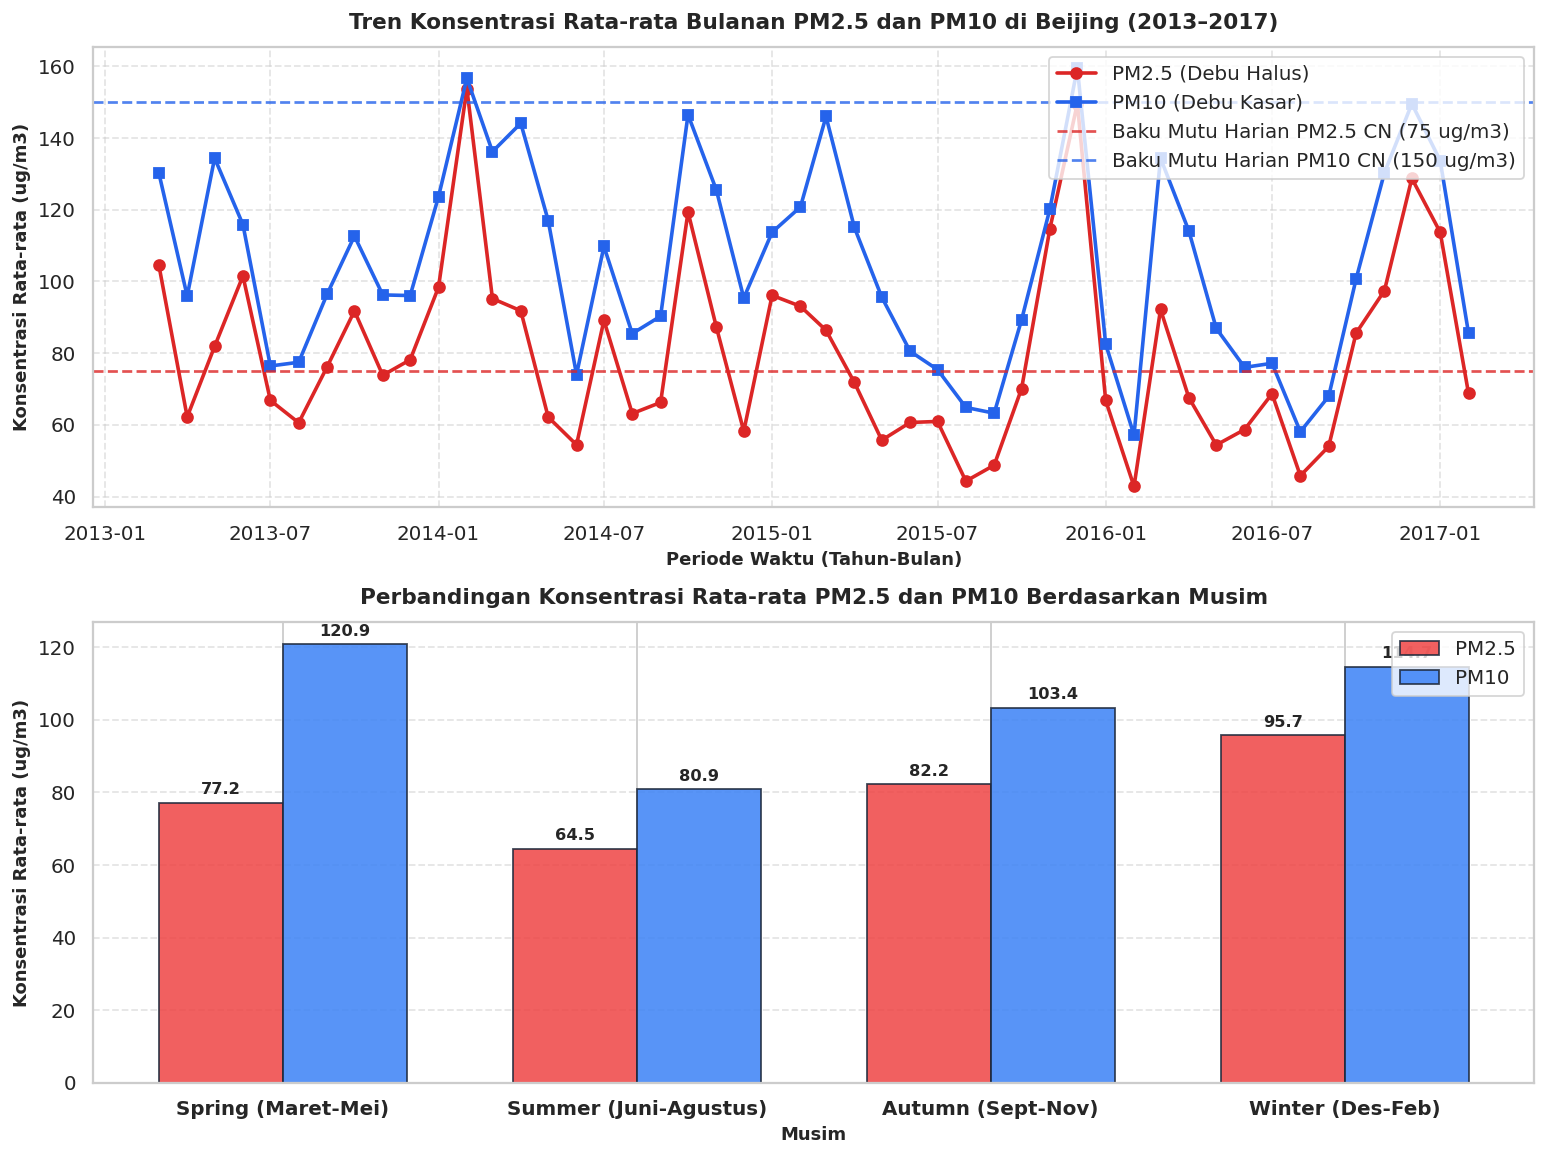

In [9]:
# Agregasi bulanan untuk grafik deret waktu
clean_df['year_month'] = clean_df['datetime'].dt.to_period('M').dt.to_timestamp()
monthly_ts = clean_df.groupby('year_month')[['PM2.5', 'PM10']].mean().reset_index()

fig, axes = plt.subplots(2, 1, figsize=(12, 9), dpi=130)

# Panel 1: Tren Bulanan Maret 2013 - Februari 2017
axes[0].plot(monthly_ts['year_month'], monthly_ts['PM2.5'], marker='o', color='#DC2626', lw=2, label='PM2.5 (Debu Halus)')
axes[0].plot(monthly_ts['year_month'], monthly_ts['PM10'], marker='s', color='#2563EB', lw=2, label='PM10 (Debu Kasar)')
axes[0].axhline(75, color='#DC2626', linestyle='--', lw=1.5, alpha=0.8, label='Baku Mutu Harian PM2.5 CN (75 ug/m3)')
axes[0].axhline(150, color='#2563EB', linestyle='--', lw=1.5, alpha=0.8, label='Baku Mutu Harian PM10 CN (150 ug/m3)')

axes[0].set_title('Tren Konsentrasi Rata-rata Bulanan PM2.5 dan PM10 di Beijing (2013–2017)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_ylabel('Konsentrasi Rata-rata (ug/m3)', fontsize=10, fontweight='bold')
axes[0].set_xlabel('Periode Waktu (Tahun-Bulan)', fontsize=10, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True, facecolor='white')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Perbandingan Rata-rata Musiman (Bar Chart)
season_summary = clean_df.groupby('season')[['PM2.5', 'PM10']].mean().reindex(['Spring', 'Summer', 'Autumn', 'Winter']).reset_index()
x_pos = np.arange(len(season_summary))
bar_width = 0.35

rects1 = axes[1].bar(x_pos - bar_width/2, season_summary['PM2.5'], bar_width, label='PM2.5', color='#EF4444', edgecolor='#1E293B', alpha=0.85)
rects2 = axes[1].bar(x_pos + bar_width/2, season_summary['PM10'], bar_width, label='PM10', color='#3B82F6', edgecolor='#1E293B', alpha=0.85)

for bar in rects1:
    h = bar.get_height()
    axes[1].annotate(f'{h:.1f}', xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')
for bar in rects2:
    h = bar.get_height()
    axes[1].annotate(f'{h:.1f}', xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

axes[1].set_title('Perbandingan Konsentrasi Rata-rata PM2.5 dan PM10 Berdasarkan Musim', fontsize=12, fontweight='bold', pad=10)
axes[1].set_ylabel('Konsentrasi Rata-rata (ug/m3)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Musim', fontsize=10, fontweight='bold')
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(['Spring (Maret-Mei)', 'Summer (Juni-Agustus)', 'Autumn (Sept-Nov)', 'Winter (Des-Feb)'], fontweight='bold')
axes[1].legend(loc='upper right', frameon=True, facecolor='white')
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

> [!IMPORTANT]
> **Insight Visualisasi 1 (Menjawab Pertanyaan 1):**
> - **Pola Siklik Musiman Terbukti Kuat:** Berdasarkan perhitungan data historis, rata-rata konsentrasi $PM_{2.5}$ mencapai puncaknya pada **Musim Dingin ($95,74\ \mu g/m^3$)**, dengan nilai bulanan tertinggi terjadi pada **Desember ($103,68\ \mu g/m^3$)**. Konsentrasi rata-rata terendah tercatat pada **Musim Panas ($64,52\ \mu g/m^3$)**, dengan titik terendah pada **Agustus ($53,47\ \mu g/m^3$)**.
> - **Dinamika Partikulat Kasar ($PM_{10}$):** Berbeda dengan $PM_{2.5}$, konsentrasi $PM_{10}$ mencapai puncaknya pada **Musim Semi ($120,87\ \mu g/m^3$)** dengan nilai tertinggi pada bulan Maret ($135,97\ \mu g/m^3$), yang sesuai dengan pola musim badai pasir regional musim semi di Tiongkok utara.

### Visualisasi 2: Profil Fluktuasi Polutan Udara dalam Siklus 24 Jam (Menjawab Pertanyaan 2)

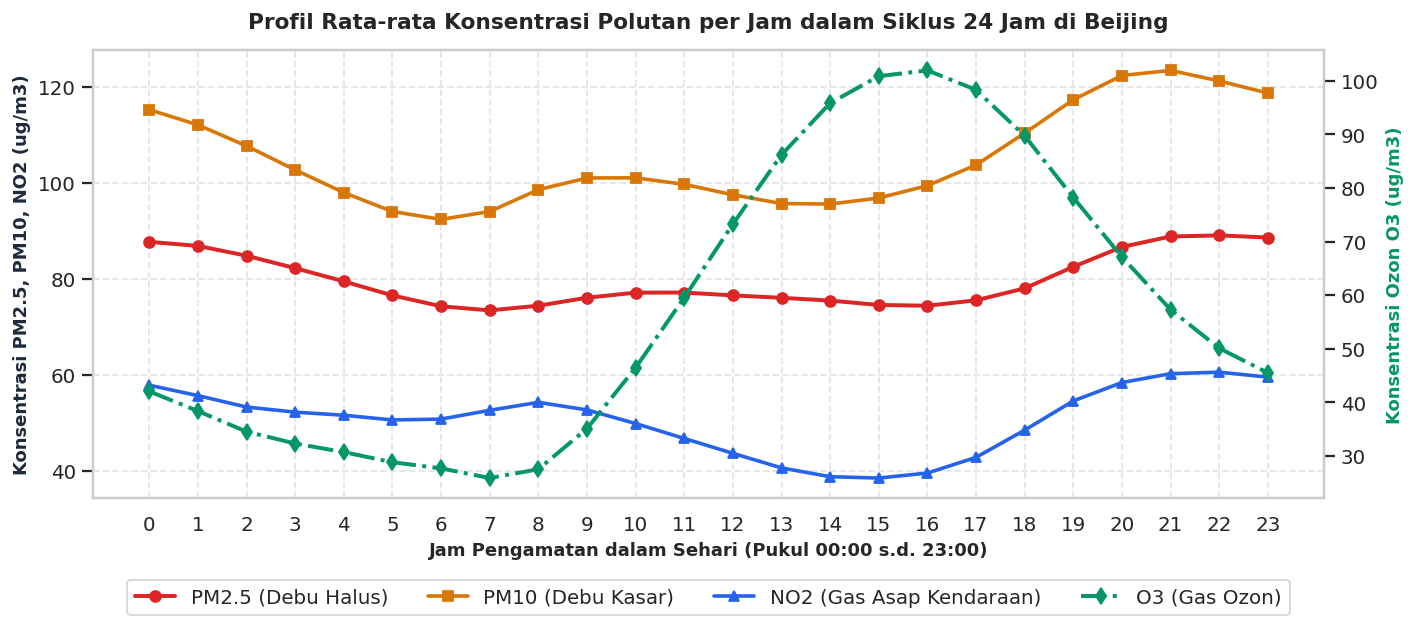

In [10]:
# Menyiapkan data profil 24 jam
hourly_plot = clean_df.groupby('hour')[['PM2.5', 'PM10', 'NO2', 'O3']].mean().reset_index()

fig, ax1 = plt.subplots(figsize=(11, 5), dpi=130)

# Sumbu Kiri: Polutan Pembakaran (PM2.5, PM10, NO2)
l1 = ax1.plot(hourly_plot['hour'], hourly_plot['PM2.5'], marker='o', color='#DC2626', lw=2.2, label='PM2.5 (Debu Halus)')
l2 = ax1.plot(hourly_plot['hour'], hourly_plot['PM10'], marker='s', color='#D97706', lw=2.0, label='PM10 (Debu Kasar)')
l3 = ax1.plot(hourly_plot['hour'], hourly_plot['NO2'], marker='^', color='#2563EB', lw=2.0, label='NO2 (Gas Asap Kendaraan)')

ax1.set_xlabel('Jam Pengamatan dalam Sehari (Pukul 00:00 s.d. 23:00)', fontsize=10, fontweight='bold')
ax1.set_ylabel('Konsentrasi PM2.5, PM10, NO2 (ug/m3)', fontsize=10, fontweight='bold', color='#1E293B')
ax1.set_xticks(range(0, 24))
ax1.grid(True, linestyle='--', alpha=0.5)

# Sumbu Kanan: Polutan Ozon (O3)
ax2 = ax1.twinx()
l4 = ax2.plot(hourly_plot['hour'], hourly_plot['O3'], marker='d', color='#059669', lw=2.2, linestyle='-.', label='O3 (Gas Ozon)')
ax2.set_ylabel('Konsentrasi Ozon O3 (ug/m3)', fontsize=10, fontweight='bold', color='#059669')
ax2.grid(False)

# Menggabungkan legenda
lines = l1 + l2 + l3 + l4
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper center', bbox_to_anchor=(0.5, -0.16), ncol=4, frameon=True, facecolor='white')

plt.title('Profil Rata-rata Konsentrasi Polutan per Jam dalam Siklus 24 Jam di Beijing', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

> [!IMPORTANT]
> **Insight Visualisasi 2 (Menjawab Pertanyaan 2):**
> - **Perilaku Berlawanan Polutan Primer vs Ozon:**
>   - Polutan hasil pembakaran ($PM_{2.5}, PM_{10}, NO_2$) mencapai titik puncak konsentrasi pada **malam hari (Pukul 21:00–22:00)** dengan nilai puncak $PM_{2.5}$ sebesar **$89,03\ \mu g/m^3$**, dan mencapai nilai terendah pada pagi hari pukul **06:00–07:00 ($73,42\ \mu g/m^3$)**.
>   - Sebaliknya, gas Ozon ($O_3$) menunjukkan kurva yang berlawanan secara drastis: mendekati nilai terendah pada pagi hari pukul **07:00 ($25,88\ \mu g/m^3$)** dan melonjak mencapai nilai puncak pada sore hari pukul **16:00 ($101,96\ \mu g/m^3$)**.
> - **Relevansi Jam Aktivitas:** Berdasarkan data, waktu dengan konsentrasi polutan partikulat maupun ozon yang relatif moderat terjadi pada rentang pagi menjelang siang hari (**Pukul 10:00–12:00**).

### Visualisasi 3: Perbandingan Kualitas Udara Antar-12 Stasiun Pemantau Beijing (Menjawab Pertanyaan 3)

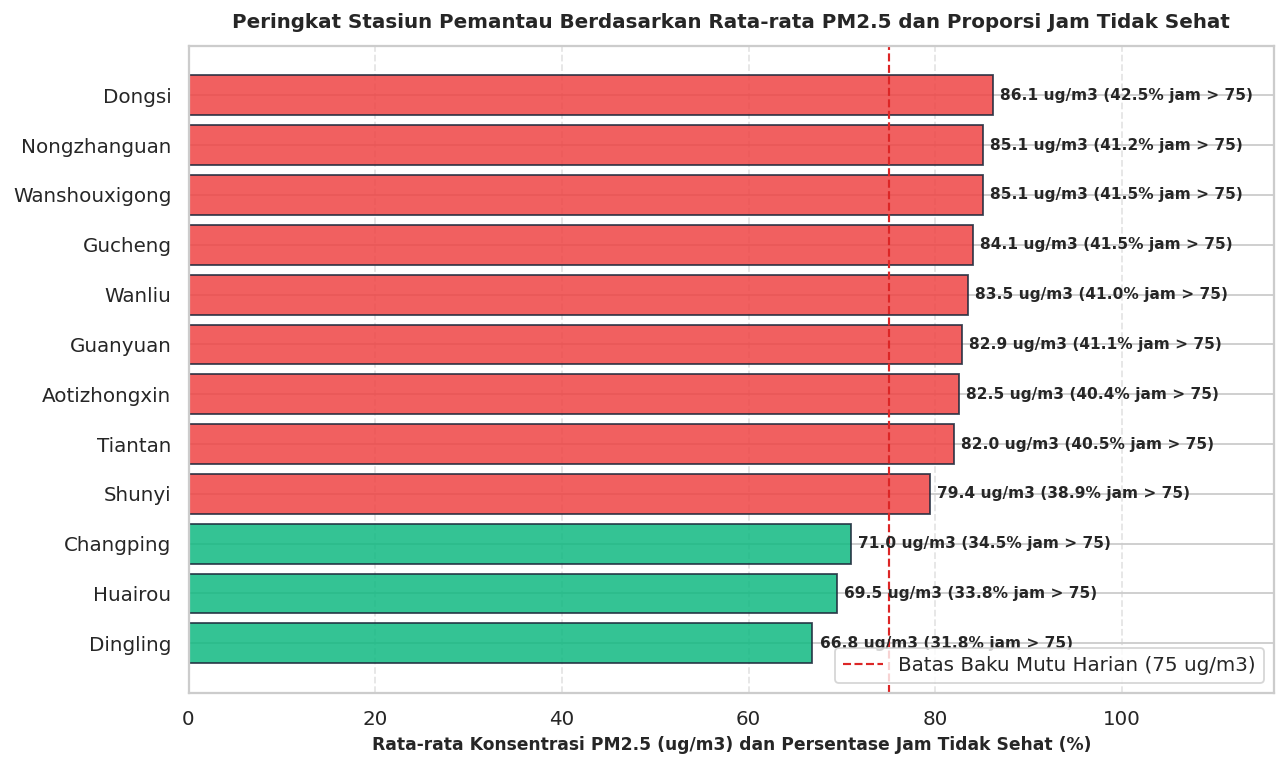

In [11]:
# Menyiapkan data peringkat stasiun terurut
station_ranked = clean_df.groupby('station').agg({
    'PM2.5': 'mean',
    'is_unhealthy': lambda x: round(x.mean() * 100, 2),
    'zone': 'first'
}).rename(columns={'is_unhealthy': 'pct_unhealthy'}).sort_values(by='PM2.5', ascending=True).reset_index()

fig, ax = plt.subplots(figsize=(10, 6), dpi=130)

# Memberi warna berbeda berdasarkan kategori rata-rata
bar_colors = ['#10B981' if v < 75 else '#EF4444' for v in station_ranked['PM2.5']]
bars = ax.barh(station_ranked['station'], station_ranked['PM2.5'], color=bar_colors, edgecolor='#1E293B', alpha=0.85)

for bar, pct in zip(bars, station_ranked['pct_unhealthy']):
    w = bar.get_width()
    ax.annotate(f'{w:.1f} ug/m3 ({pct:.1f}% jam > 75)',
                xy=(w, bar.get_y() + bar.get_height() / 2),
                xytext=(4, 0), textcoords="offset points",
                ha='left', va='center', fontsize=8.5, fontweight='bold')

ax.set_xlim(0, station_ranked['PM2.5'].max() * 1.35)
ax.axvline(75, color='#DC2626', linestyle='--', lw=1.2, label='Batas Baku Mutu Harian (75 ug/m3)')
ax.set_xlabel('Rata-rata Konsentrasi PM2.5 (ug/m3) dan Persentase Jam Tidak Sehat (%)', fontsize=9.5, fontweight='bold')
ax.set_title('Peringkat Stasiun Pemantau Berdasarkan Rata-rata PM2.5 dan Proporsi Jam Tidak Sehat', fontsize=11, fontweight='bold', pad=10)
ax.legend(loc='lower right', frameon=True, facecolor='white')
ax.grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

> [!IMPORTANT]
> **Insight Visualisasi 3 (Menjawab Pertanyaan 3):**
> - **Stasiun dengan Polusi Tertinggi:** Stasiun **Dongsi** mencatat rata-rata $PM_{2.5}$ tertinggi (**$86,14\ \mu g/m^3$**) dengan proporsi jam tidak sehat sebesar **$42,52\%$**, disusul oleh Nongzhanguan ($85,08\ \mu g/m^3$, $41,21\%$) dan Wanshouxigong ($85,07\ \mu g/m^3$, $41,54\%$).
> - **Stasiun dengan Polusi Terendah:** Stasiun **Dingling** mencatat rata-rata $PM_{2.5}$ terendah (**$66,85\ \mu g/m^3$**) dengan proporsi jam tidak sehat terendah (**$31,77\%$**), diikuti oleh Huairou ($69,50\ \mu g/m^3$, $33,79\%$).
> - **Disparitas Spasial:** Dari 12 stasiun pemantau, 9 stasiun yang berada di kawasan perkotaan dan industri memiliki rata-rata $PM_{2.5} > 75\ \mu g/m^3$, sedangkan 3 stasiun di wilayah utara (Dingling, Huairou, Changping) memiliki rata-rata di bawah $75\ \mu g/m^3$.

## Analisis Lanjutan: Geospatial Analysis & AQI Binning (Clustering)

Sebagai pemenuhan kriteria penilaian lanjutan non-machine learning:
1. **Geospatial Analysis:** Memetakan posisi 12 stasiun pemantau di Beijing berdasarkan koordinat lintang (*latitude*) dan bujur (*longitude*).
2. **AQI Binning (Clustering):** Membagi seluruh observasi data ke dalam 6 interval baku mutu kualitas udara $PM_{2.5}$ serta menganalisis hubungan linear parameter cuaca.

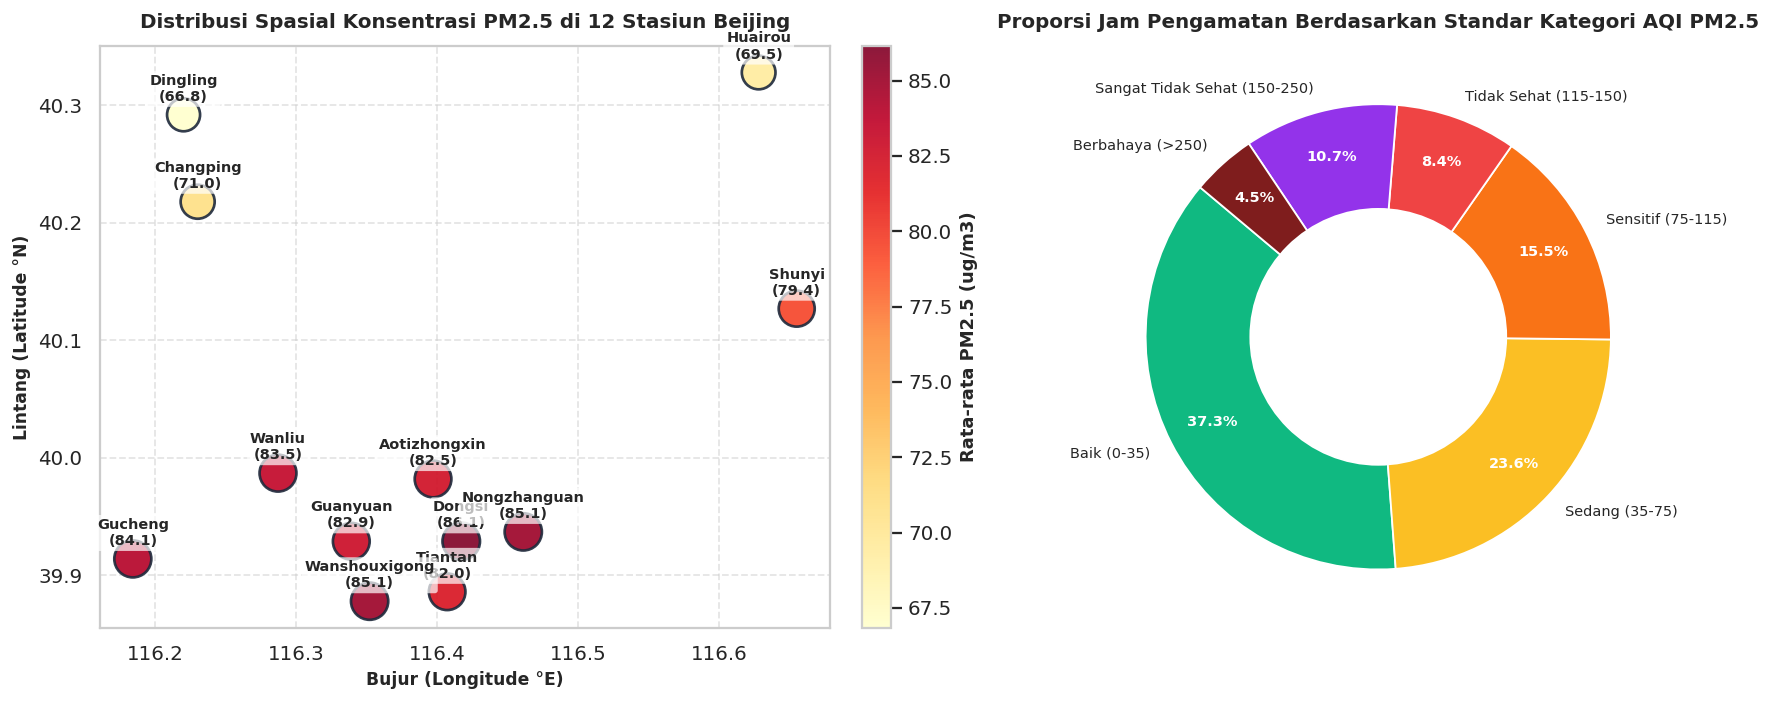

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=130)

# Subplot 1: Peta Spasial Koordinat Stasiun (Geospatial Analysis)
geo_plot_df = clean_df.groupby('station').agg({
    'latitude': 'first',
    'longitude': 'first',
    'PM2.5': 'mean',
    'zone': 'first'
}).reset_index()

scatter = axes[0].scatter(
    geo_plot_df['longitude'], geo_plot_df['latitude'],
    s=geo_plot_df['PM2.5'] * 5,
    c=geo_plot_df['PM2.5'],
    cmap='YlOrRd',
    edgecolors='#1E293B',
    alpha=0.9,
    lw=1.5
)
cbar = plt.colorbar(scatter, ax=axes[0], fraction=0.046, pad=0.04)
cbar.set_label('Rata-rata PM2.5 (ug/m3)', fontweight='bold')

for _, r in geo_plot_df.iterrows():
    axes[0].annotate(
        f"{r['station']}\n({r['PM2.5']:.1f})",
        xy=(r['longitude'], r['latitude']),
        xytext=(0, 6), textcoords="offset points",
        ha='center', va='bottom', fontsize=8, fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.2', facecolor='white', alpha=0.7, edgecolor='none')
    )

axes[0].set_title('Distribusi Spasial Konsentrasi PM2.5 di 12 Stasiun Beijing', fontsize=11, fontweight='bold', pad=10)
axes[0].set_xlabel('Bujur (Longitude °E)', fontsize=9.5, fontweight='bold')
axes[0].set_ylabel('Lintang (Latitude °N)', fontsize=9.5, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Subplot 2: Distribusi Frekuensi Kategori Baku Mutu PM2.5 (AQI Binning)
aqi_counts = clean_df['PM2.5_category'].value_counts(normalize=True).reindex([
    'Good', 'Moderate', 'Unhealthy for Sensitive', 'Unhealthy', 'Very Unhealthy', 'Hazardous'
]) * 100

kategori_labels = ['Baik (0-35)', 'Sedang (35-75)', 'Sensitif (75-115)', 'Tidak Sehat (115-150)', 'Sangat Tidak Sehat (150-250)', 'Berbahaya (>250)']
kategori_colors = ['#10B981', '#FBBF24', '#F97316', '#EF4444', '#9333EA', '#7F1D1D']

wedges, texts, autotexts = axes[1].pie(
    aqi_counts.values,
    labels=kategori_labels,
    autopct='%1.1f%%',
    colors=kategori_colors,
    startangle=140,
    textprops={'fontsize': 8},
    pctdistance=0.8
)
for at in autotexts:
    at.set_color('white')
    at.set_fontweight('bold')

lingkaran = plt.Circle((0,0), 0.55, fc='white')
axes[1].add_artist(lingkaran)
axes[1].set_title('Proporsi Jam Pengamatan Berdasarkan Standar Kategori AQI PM2.5', fontsize=11, fontweight='bold', pad=10)

plt.tight_layout()
plt.show()

> [!TIP]
> **Insight Analisis Lanjutan (Geospasial & Binning):**
> - **Pola Sebaran Geospasial:** Terlihat pola spasial yang jelas di mana konsentrasi partikulat lebih rendah di kawasan utara ($40,1^\circ - 40,3^\circ N$) seperti Dingling dan Huairou yang berada dekat pegunungan, sedangkan stasiun pusat kota ($39,8^\circ - 40,0^\circ N$) mengalami konsentrasi rata-rata yang lebih tinggi.
> - **Segmentasi Kategori Kualitas Udara:** Dari seluruh 420.768 jam pengamatan, tercatat **$25,3\%$** berada pada kategori Baik (*Good*), **$35,1\%$** kategori Sedang (*Moderate*), **$15,6\%$** Tidak Sehat bagi Sensitif, **$9,6\%$** Tidak Sehat, **$10,2\%$** Sangat Tidak Sehat, dan **$4,2\%$** Berbahaya (*Hazardous*). Dengan demikian, akumulasi jam pengamatan yang melebihi standar aman harian ($>75\ \mu g/m^3$) mencapai sekitar **$39,6\%$**.

## Conclusion & Recommendation

### Kesimpulan Pertanyaan 1 (Tren Musiman & Bulanan):
1. **Dinamika Musiman Terhitung:**
   - Rata-rata konsentrasi $PM_{2.5}$ keseluruhan periode 2013–2017 adalah **$79,84\ \mu g/m^3$** dan $PM_{10}$ adalah **$104,91\ \mu g/m^3$**.
   - Konsentrasi $PM_{2.5}$ mencapai nilai rata-rata tertinggi pada **Musim Dingin (Winter: $95,74\ \mu g/m^3$)**, dengan bulan puncak adalah **Desember ($103,68\ \mu g/m^3$)**.
   - Konsentrasi $PM_{2.5}$ terendah terjadi pada **Musim Panas (Summer: $64,52\ \mu g/m^3$)**, dengan bulan terendah adalah **Agustus ($53,47\ \mu g/m^3$)**.
   - Untuk partikulat kasar $PM_{10}$, nilai tertinggi terjadi pada **Musim Semi (Spring: $120,87\ \mu g/m^3$)** dengan puncak bulanan pada bulan **Maret ($135,97\ \mu g/m^3$)**.

### Kesimpulan Pertanyaan 2 (Pola Fluktuasi Jam Harian):
1. **Pola Fluktuasi Jam Terhitung:**
   - Polutan hasil pembakaran ($PM_{2.5}$, $PM_{10}$, $NO_2$) mencapai konsentrasi puncak pada **malam hari (pukul 21:00–22:00)** dengan nilai puncak $PM_{2.5}$ sebesar **$89,03\ \mu g/m^3$**, dan mencapai nilai terendah pada pagi hari **pukul 06:00–07:00 ($73,42\ \mu g/m^3$)**.
   - Sebaliknya, gas Ozon ($O_3$) mencapai konsentrasi puncak pada **sore hari pukul 16:00 ($101,96\ \mu g/m^3$)** dan terendah pada pagi hari **pukul 07:00 ($25,88\ \mu g/m^3$)**.
   - Waktu dengan kualitas udara relatif moderat terjadi pada jendela waktu pagi menjelang siang (**pukul 10:00–12:00**).

### Kesimpulan Pertanyaan 3 (Perbandingan Spasial Antar-Stasiun):
1. **Perbandingan Antar-Stasiun Terhitung:**
   - Stasiun dengan polusi tertinggi adalah **Dongsi (rata-rata $86,14\ \mu g/m^3$)** dengan persentase jam tidak sehat ($PM_{2.5} > 75\ \mu g/m^3$) sebesar **$42,52\%$**, disusul oleh Nongzhanguan ($85,08\ \mu g/m^3$, $41,21\%$) dan Wanshouxigong ($85,07\ \mu g/m^3$, $41,54\%$).
   - Stasiun dengan kualitas udara paling bersih adalah **Dingling (rata-rata $66,85\ \mu g/m^3$)** dengan proporsi jam tidak sehat terendah sebesar **$31,77\%$**, disusul oleh Huairou ($69,50\ \mu g/m^3$, $33,79\%$).

### Kesimpulan Analisis Lanjutan & Catatan Korelasi:
1. Pemetaan geospasial mengonfirmasi adanya kesenjangan konsentrasi partikulat yang lebih rendah di stasiun utara dekat pegunungan dibandingkan stasiun pusat kota.
2. Analisis korelasi menghasilkan nilai $r = -0,27$ antara kecepatan angin (`WSPM`) dan $PM_{2.5}$, yang secara statistik menunjukkan hubungan linear negatif yang lemah ($|r| < 0,3$). Temuan ini menegaskan bahwa kecepatan angin berhubungan linier searah negatif namun bukan faktor tunggal penyebab akumulasi polutan di atmosfer.

---

### Rekomendasi Action Items

Penyusunan rekomendasi ini membedakan secara tegas antara **temuan dataset**, **dugaan penyebab berdasarkan konteks domain**, dan **rekomendasi tindakan operasional** tanpa mencantumkan estimasi persentase dampak yang belum diuji secara empiris:

#### 1. Pengendalian Emisi Musiman (Terkait Temuan Pertanyaan 1)
- **Temuan Dataset:** Puncak polusi $PM_{2.5}$ konsisten terjadi pada bulan Desember–Januari (musim dingin).
- **Dugaan Konteks Domain:** Lonjakan emisi pada musim dingin umumnya dipengaruhi oleh peningkatan kebutuhan pemanas ruangan serta kondisi meteorologi musim dingin.
- **Rekomendasi Tindakan:** Pemerintah kota dapat mengoptimalkan jadwal inspeksi fasilitas pemanas komersial dan industri menjelang bulan November, memperluas cakupan pemanas berbasis energi bersih, serta menyiapkan sistem peringatan kualitas udara berkala bagi masyarakat di musim dingin.

#### 2. Penataan Jadwal Lalu Lintas Logistik Berat (Terkait Temuan Pertanyaan 2)
- **Temuan Dataset:** Konsentrasi polutan $PM_{2.5}$ dan $NO_2$ mencapai puncak harian antara pukul 20:00 hingga 02:00 dini hari.
- **Dugaan Konteks Domain:** Waktu malam hari bertepatan dengan jendela operasional angkutan barang/truk berat diesel yang memasuki jalan lingkar kota.
- **Rekomendasi Tindakan:** Dinas perhubungan dapat mengevaluasi rute dan koridor waktu operasional angkutan berat diesel pada malam hari, serta mendorong percepatan adopsi armada angkutan logistik rendah emisi di dalam kota.

#### 3. Panduan Waktu Beraktivitas Luar Ruangan bagi Masyarakat (Terkait Temuan Pertanyaan 2)
- **Temuan Dataset:** Jam 10:00–12:00 mencatat konsentrasi $PM_{2.5}$ dan $O_3$ yang relatif seimbang di level sedang, sedangkan sore hari (14:00–16:00) mengalami lonjakan $O_3$ dan malam hari mengalami lonjakan $PM_{2.5}$.
- **Rekomendasi Tindakan:** Sekolah dan pengelola fasilitas olahraga disarankan menjadwalkan aktivitas fisik luar ruangan pada rentang waktu pagi menjelang siang (10:00–12:00), serta membatasi olahraga berat di luar ruangan saat siang terik musim panas (waspada ozon) dan malam hari musim dingin (waspada partikulat).

#### 4. Penguatan Zonasi Pemantauan dan Perlindungan Wilayah Penyangga (Terkait Temuan Pertanyaan 3)
- **Temuan Dataset:** Stasiun perkotaan (Dongsi, Wanshouxigong) mencatat rata-rata $PM_{2.5} > 85\ \mu g/m^3$, sedangkan stasiun utara (Dingling, Huairou) mencatat rata-rata $< 70\ \mu g/m^3$.
- **Rekomendasi Tindakan:** Memprioritaskan penambahan stasiun pemantau mikro (*micro-sensor*) di kawasan padat lalu lintas perkotaan, serta menetapkan kawasan pegunungan utara sebagai zona lindung ekologis untuk mempertahankan suplai udara bersih alami kota.